# 05 Error analysis
Run first (per model, per seed):
`python -m src.evaluation.error_analysis --config <config> --seed 0`

Questions: are Parthenium / Snake weed / Chinee apple errors concentrated in particular capture sessions or days? What does the model look at when it is wrong?

In [1]:
import json, pathlib
import pandas as pd
from IPython.display import Image, display
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
M = ROOT / "results" / "metrics"

def table(runs):
    rows = []
    for r in runs:
        d = json.loads((M / f"{r}.json").read_text())["splits"]
        rows.append({"run": r, **{f"{s} {k}": d[s]["model"][k] for s in ("val", "test") for k in ("macro_f1", "accuracy")}})
    return pd.DataFrame(rows).set_index("run").round(3)

def summary():
    p = M / "multiseed_summary.json"
    if not p.exists():
        return "run src.evaluation.aggregate first"
    return pd.DataFrame({k: {"seeds": len(v["seeds"]), "val": f"{v['val_mean']:.3f} ± {v['val_std']:.3f}",
                             "test": f"{v['test_mean']:.3f} ± {v['test_std']:.3f}"} for k, v in json.loads(p.read_text()).items()}).T
EA = ROOT / "results" / "error_analysis"
RUN = "resnet50_aug_geo_30ep_s0"   # change to the run being analysed
pred = pd.read_csv(EA / f"{RUN}_test_predictions.csv")
pred.groupby("true").correct.mean().round(3)

true
Chinee apple      0.782
Lantana           0.878
Negative          0.811
Parkinsonia       0.883
Parthenium        0.549
Prickly acacia    0.930
Rubber vine       0.812
Siam weed         0.963
Snake weed        0.857
Name: correct, dtype: float64

## Confusions for the three focus species

In [2]:
for sp in ["Parthenium", "Snake weed", "Chinee apple"]:
    d = pred[pred.true == sp]
    print(sp, f"- {int((~d.correct).sum())}/{len(d)} wrong"); print(d[~d.correct].pred.value_counts().head(4).to_string(), "\n")

Parthenium - 78/173 wrong
pred
Prickly acacia    29
Negative          26
Snake weed         8
Chinee apple       7 

Snake weed - 29/203 wrong
pred
Chinee apple    9
Negative        7
Siam weed       6
Lantana         5 

Chinee apple - 49/225 wrong
pred
Snake weed     18
Negative       14
Lantana         8
Rubber vine     5 



## Session / date concentration
If a few sessions hold most of a species' errors, the confusion is a capture-condition effect (lighting, background) rather than a species effect.

In [3]:
for sp in ["Parthenium", "Snake weed", "Chinee apple"]:
    print(sp); display(pd.read_csv(EA / f"{RUN}_test_sessions_{sp.replace(' ', '_')}.csv").head(5))

Parthenium


,session,n,errors,error_rate
0,513,16,13,0.812500
1,506,8,8,1.000000
2,512,8,8,1.000000
3,528,8,6,0.750000
4,511,7,5,0.714286


Snake weed


,session,n,errors,error_rate
0,20,50,5,0.100000
1,878,14,4,0.285714
2,62,16,4,0.250000
3,36,3,3,1.000000
4,100,42,3,0.071429


Chinee apple


,session,n,errors,error_rate
0,355,34,18,0.529412
1,5,38,11,0.289474
2,104,42,5,0.119048
3,107,26,4,0.153846
4,195,4,2,0.500000


## Grad-CAM (most confident errors, map for the wrongly predicted class)

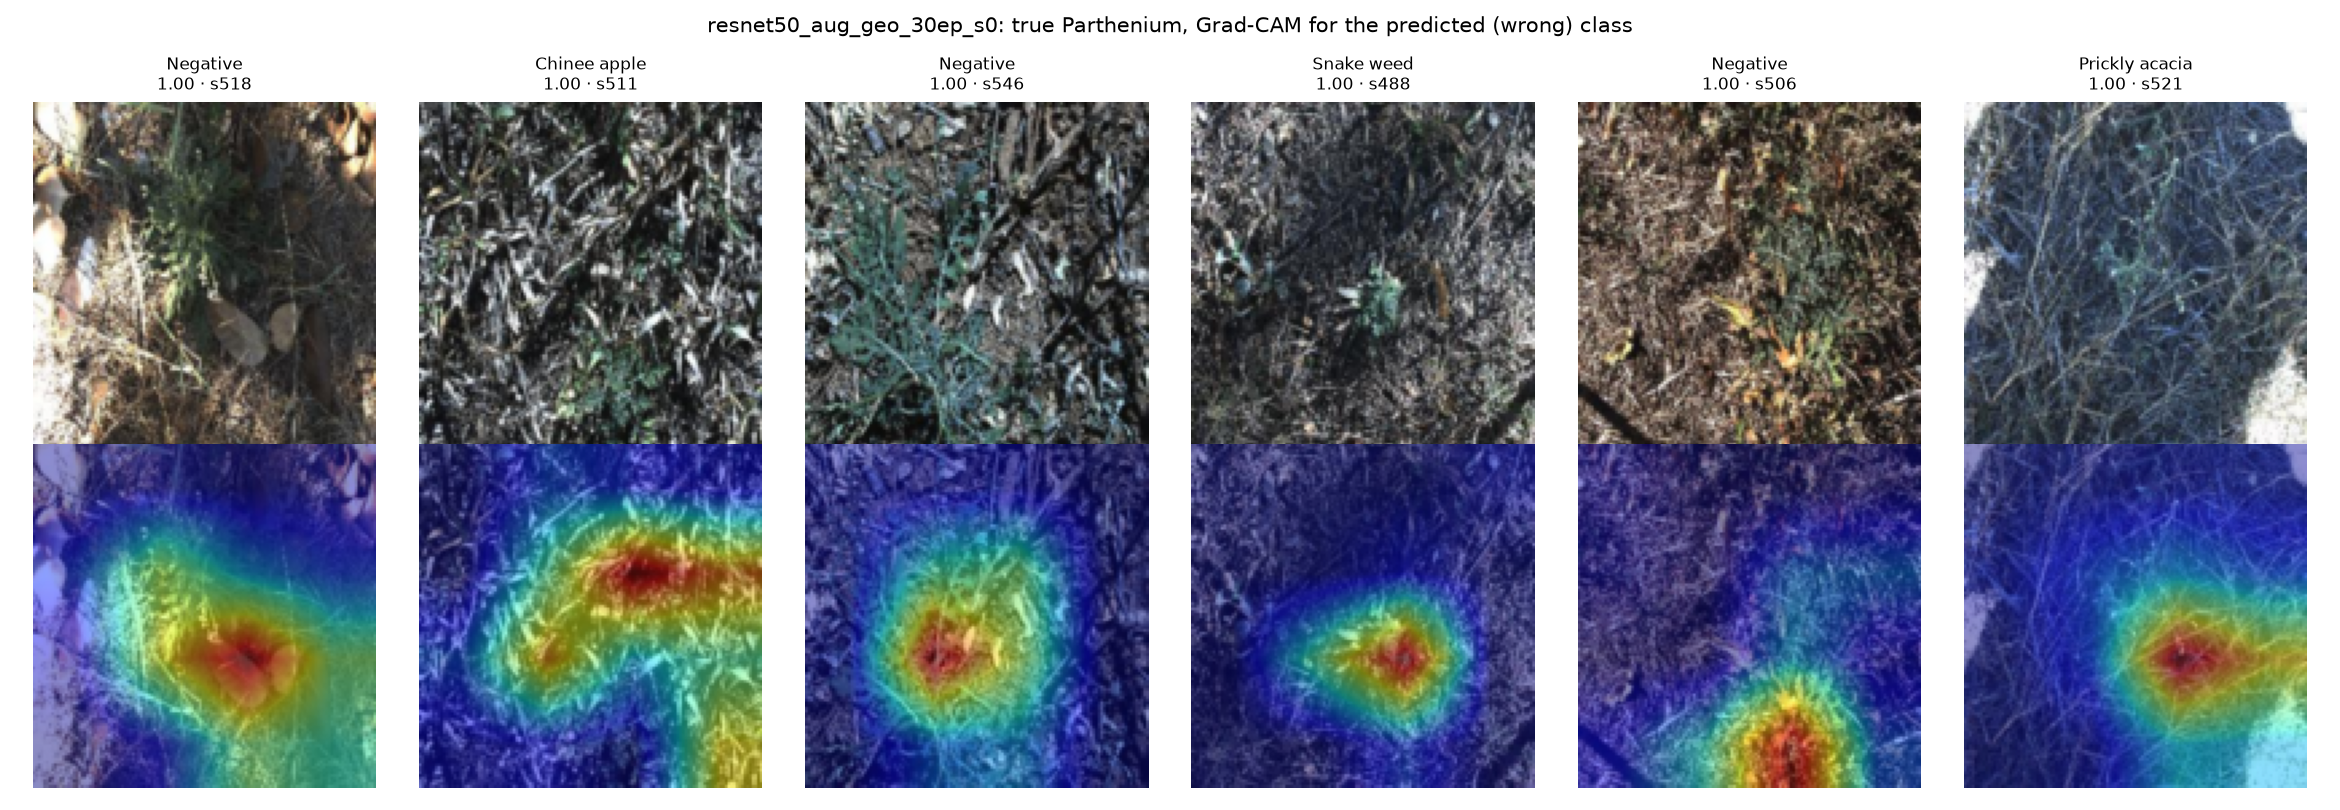

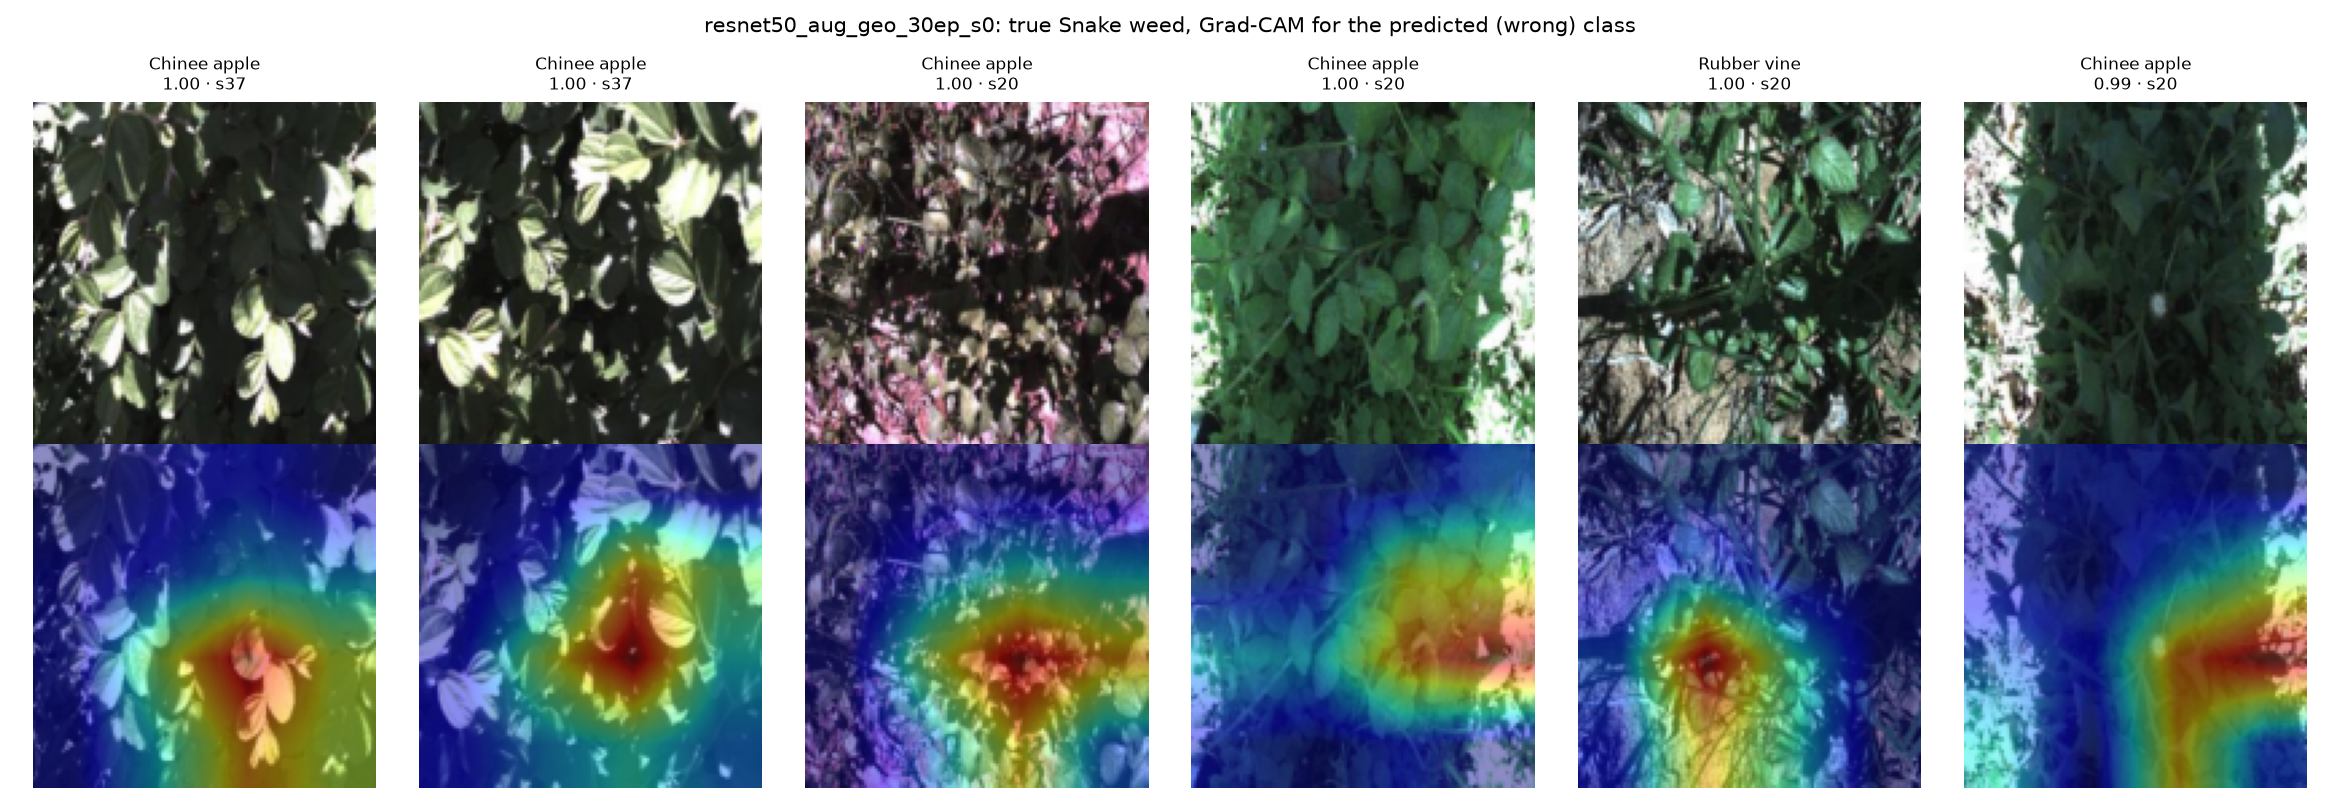

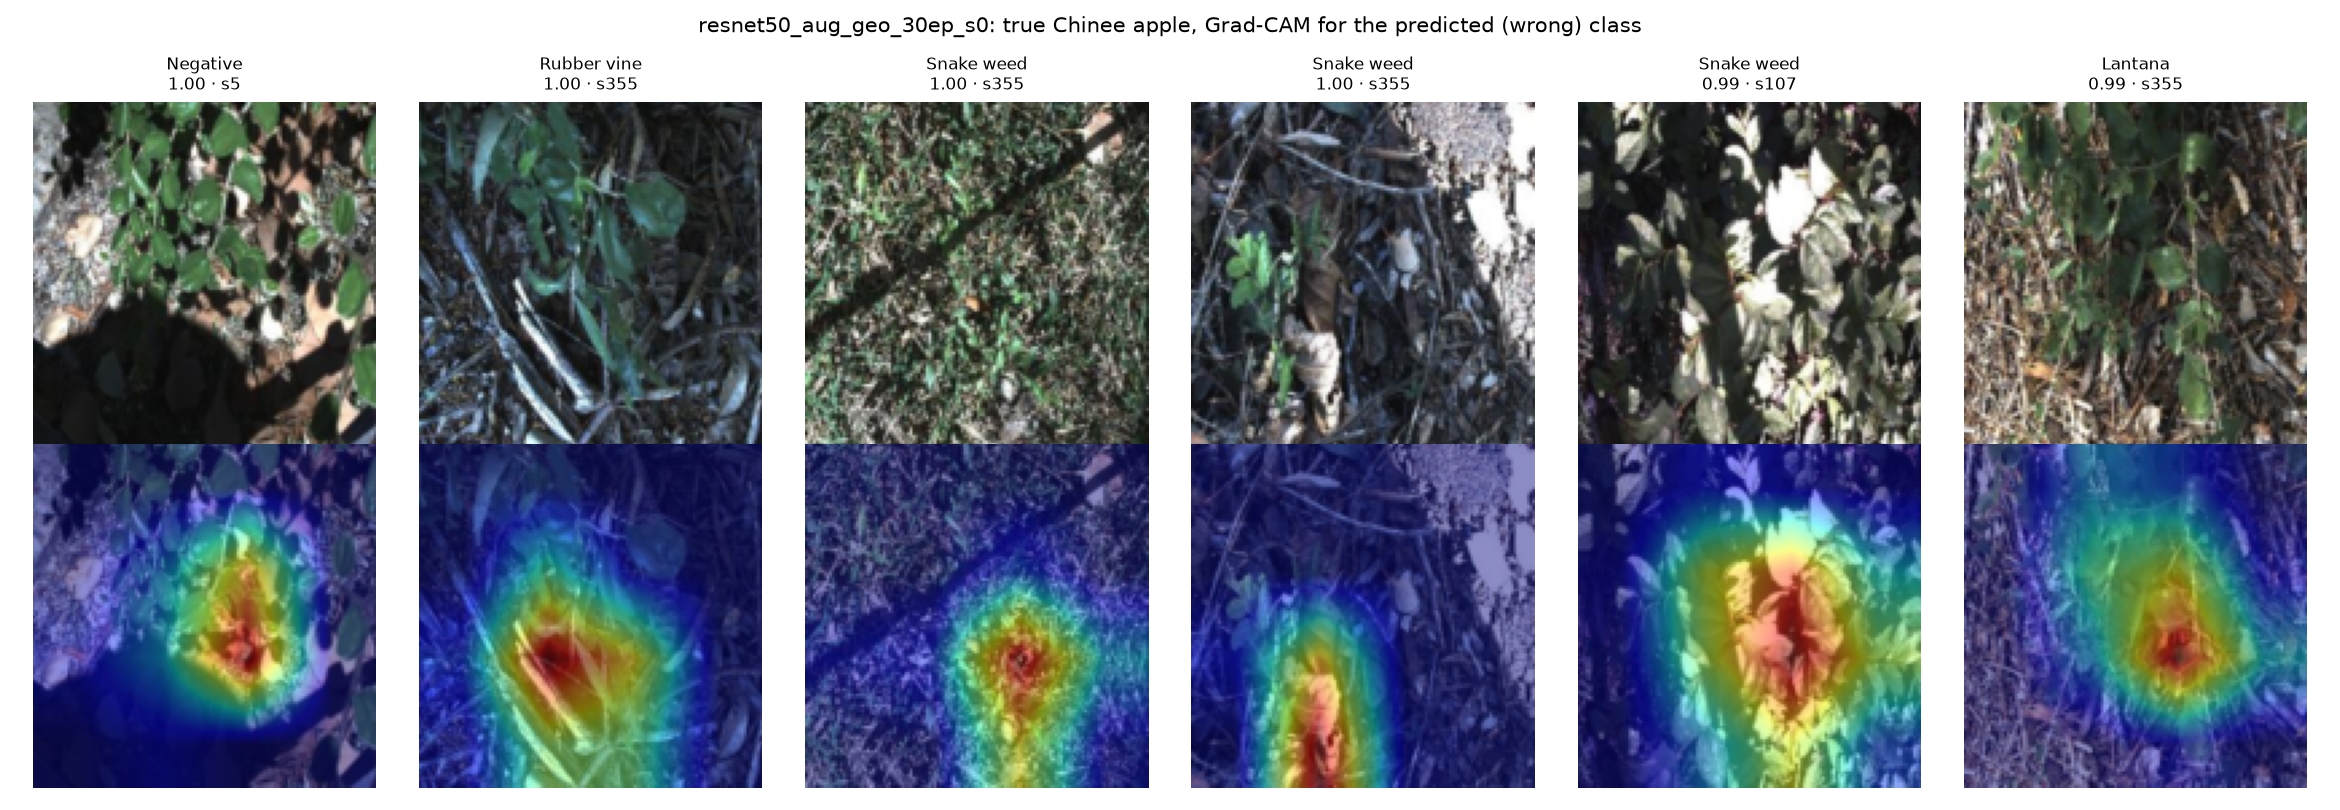

In [4]:
for sp in ["Parthenium", "Snake weed", "Chinee apple"]:
    display(Image(str(EA / f"{RUN}_gradcam_{sp.replace(' ', '_')}.png")))

## Findings
_Fill in after running._